# How players age, from real stats

The trade desk's dynasty values depend on how production changes with age. This notebook builds
those curves from actual box-score points (2020–2025), the same method `build_trade_values.py`
uses, and checks them.

Points are **per game played**, so a missed season to injury doesn't read as decline (the trade
engine handles availability separately). A player with a role (6+ games, 3+ points per game)
who plays **no** games the next season counts as a zero, because washing out is part of aging.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from common import (ROOT, style, load_weekly_actuals, load_players, player_seasons,
                    POSITIONS, POS_COLORS, INK, INK_3, STAMP)

style()
pd.set_option("display.precision", 2)

players = load_players()
ps = player_seasons(load_weekly_actuals(), players).dropna(subset=["age"])
ps["age_int"] = ps.age.astype(int)
print(f"{len(ps):,} player-seasons with 6+ games")
ps.groupby("position").agg(player_seasons=("ppg", "size"), median_age=("age", "median"),
                           mean_ppg=("ppg", "mean")).loc[POSITIONS]

2,832 player-seasons with 6+ games


,player_seasons,median_age,mean_ppg
position,,,
QB,264,27.27,14.39
RB,719,25.33,6.83
WR,1161,25.52,6.37
TE,688,26.12,3.98


## 1. Year-over-year retention

For each player-season with a role, next season's points per game ÷ this season's, pooled by
position and age (point-weighted, so stars count more than fringe players). Ages are smoothed
with a 5-year triangular window.

1,417 season-to-season pairs
league-wide raw retention: 0.834 (curves below are relative to it)


,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35
QB,1.28,1.20,1.13,1.08,1.06,1.06,1.06,1.04,1.01,0.99,0.98,1.01,1.00,1.00,0.93
RB,1.10,1.10,1.08,1.05,1.02,0.97,0.91,0.84,0.78,0.77,0.69,0.63,0.53,0.65,0.81
WR,1.19,1.15,1.09,1.05,0.99,0.96,0.93,0.91,0.87,0.85,0.81,0.77,0.66,0.54,0.43
TE,1.19,1.21,1.18,1.12,1.05,1.01,1.00,0.97,0.95,0.90,0.89,0.84,0.83,0.73,0.71


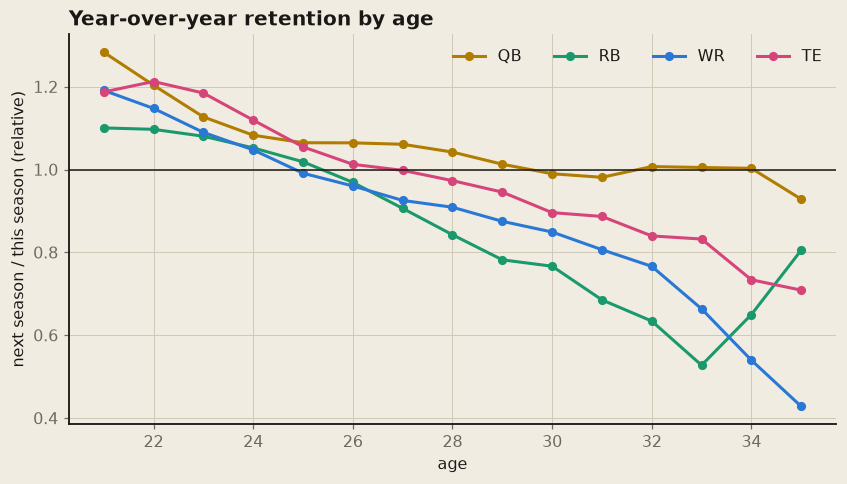

In [2]:
full = player_seasons(load_weekly_actuals(), players, min_games=1).set_index(["player_id", "season"])
base = ps[(ps.ppg >= 3) & (ps.season < ps.season.max())].copy()
nxt = [full.loc[(p, s + 1)] if (p, s + 1) in full.index else None
       for p, s in zip(base.player_id, base.season)]
base["next_ppg"] = [0.0 if n is None else n.ppg for n in nxt]
base["next_gp"] = [0 if n is None else n.games for n in nxt]
base = base[(base.next_gp == 0) | (base.next_gp >= 4)]      # 1-3 games next year: too noisy
base["next_ppg"] = np.minimum(base.next_ppg, base.ppg * 2.5)
base["dropped_out"] = base.next_gp == 0
print(f"{len(base):,} season-to-season pairs")

cells = base.groupby(["position", "age_int"]).agg(cur=("ppg", "sum"), nxt=("next_ppg", "sum"),
                                                 n=("ppg", "size")).reset_index()
league_avg = cells.nxt.sum() / cells.cur.sum()
kernel = {-2: 1, -1: 2, 0: 3, 1: 2, 2: 1}

def smoothed(pos, ages=range(21, 36)):
    c = cells[cells.position == pos].set_index("age_int")
    out = {}
    for a in ages:
        cur = sum(w * c.cur.get(a + o, 0) for o, w in kernel.items())
        nx = sum(w * c.nxt.get(a + o, 0) for o, w in kernel.items())
        out[a] = (nx + league_avg * 40) / (cur + 40) / league_avg
    return pd.Series(out)

curves = pd.DataFrame({pos: smoothed(pos) for pos in POSITIONS})
print(f"league-wide raw retention: {league_avg:.3f} (curves below are relative to it)")

fig, ax = plt.subplots()
for pos in POSITIONS:
    ax.plot(curves.index, curves[pos], marker="o", ms=5, color=POS_COLORS[pos], label=pos)
ax.axhline(1, color=INK, lw=1)
ax.set_xlabel("age")
ax.set_ylabel("next season / this season (relative)")
ax.set_title("Year-over-year retention by age")
ax.legend(ncol=4)
curves.T.round(2)

## 2. Career arc

Chaining the yearly retention gives a career arc: the expected production of a player with a
role at 22, indexed to 100. Because the curves are relative to the league-wide average, a flat
line means "keeps pace with the player pool", not "scores the same raw points".

,QB,RB,WR,TE
22,100.0,100.0,100.0,100.0
25,147.0,125.0,131.0,161.0
27,167.0,123.0,125.0,172.0
29,184.0,94.0,105.0,167.0
31,185.0,56.0,78.0,141.0
33,182.0,24.0,48.0,105.0


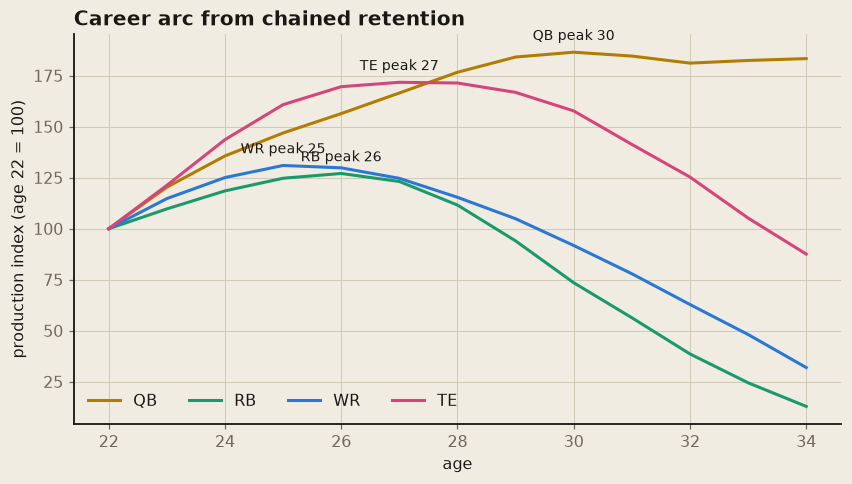

In [3]:
arc = curves.loc[22:34].shift(1).fillna(1).cumprod() * 100
fig, ax = plt.subplots()
for pos in POSITIONS:
    ax.plot(arc.index, arc[pos], color=POS_COLORS[pos], label=pos)
    peak = arc[pos].idxmax()
    ax.annotate(f"{pos} peak {peak}", (peak, arc[pos].max()), textcoords="offset points",
                xytext=(0, 8), ha="center", fontsize=9, color=INK)
ax.set_xlabel("age")
ax.set_ylabel("production index (age 22 = 100)")
ax.set_title("Career arc from chained retention")
ax.legend(ncol=4, loc="lower left")
arc.loc[[22, 25, 27, 29, 31, 33]].round(0)

## 3. Who washes out

Share of players with a role who play no games at all the next season, by age.

position,QB,RB,WR,TE
age_band,,,,
<24,0%,5%,6%,6%
24-26,11%,11%,8%,3%
27-29,8%,21%,10%,7%
30-32,15%,23%,18%,25%
33+,21%,75%,53%,27%


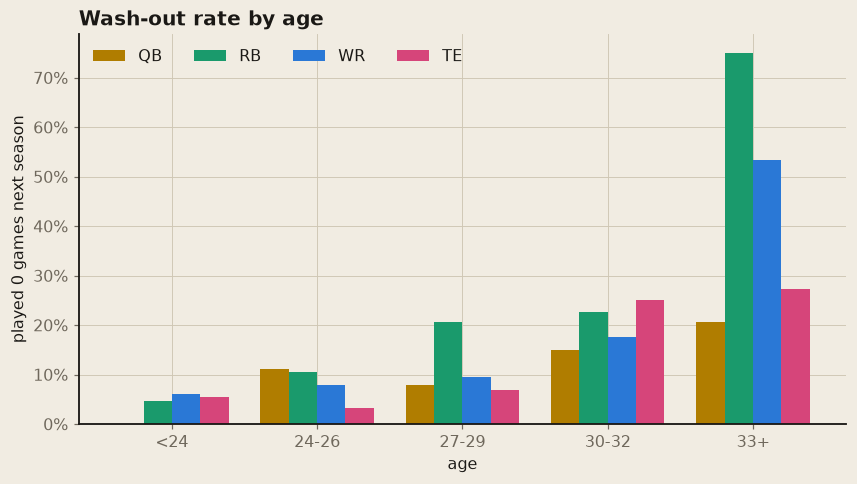

In [4]:
base["age_band"] = pd.cut(base.age, [20, 24, 27, 30, 33, 40], labels=["<24", "24-26", "27-29", "30-32", "33+"])
wash = base.pivot_table(index="age_band", columns="position", values="dropped_out", aggfunc="mean", observed=True)[POSITIONS]
ax = wash.plot(kind="bar", width=0.78, color=[POS_COLORS[p] for p in POSITIONS])
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_xlabel("age")
ax.set_ylabel("played 0 games next season")
ax.set_title("Wash-out rate by age")
ax.tick_params(axis="x", rotation=0)
ax.legend(ncol=4);
wash.style.format("{:.0%}")

## 4. Check against the trade desk

`frontend/public/data/trade_values.json` is what the live site uses. Its curves should match the
ones rebuilt here.

In [5]:
tv = json.loads((ROOT / "frontend/public/data/trade_values.json").read_text(encoding="utf-8"))["ageCurves"]
site = pd.DataFrame({p: pd.Series(v, index=range(tv["startAge"], tv["startAge"] + len(v)))
                     for p, v in tv["byPos"].items()}).loc[21:35]
# Ages 21-33 only: past that, cells are tiny and the site stops a curve from rising again
# after its peak (a 35-year-old RB "improving" is survivors, not aging).
diff = (curves.loc[21:33] - site.loc[21:33, POSITIONS]).abs()
print(f"max difference vs. site curves, ages 21-33: {diff.max().max():.3f}")
pd.concat({"here": curves.loc[[24, 27, 30, 33]], "site": site.loc[[24, 27, 30, 33], POSITIONS]}, axis=1).round(2)

max difference vs. site curves, ages 21-33: 0.026


here                    site                  
      QB    RB    WR    TE    QB    RB    WR    TE
24  1.08  1.05  1.05  1.12  1.08  1.05  1.05  1.12
27  1.06  0.91  0.93  1.00  1.06  0.91  0.92  1.00
30  0.99  0.77  0.85  0.90  0.99  0.77  0.85  0.90
33  1.00  0.53  0.66  0.83  0.98  0.53  0.66  0.83

## Takeaways

Based on 2,832 player-seasons with 6+ games and 1,417 season-to-season pairs, 2020-2025.

- **Peak ages:** WR 25, RB 26, TE 27, QB about 30. QBs then hold that level into their mid-30s
  relative to the league.
- **RBs fall off a cliff.** By 29 a typical RB is producing less, relative to the league, than
  he did at 22. By 31 he's at about 45% of his peak.
- **WRs decline more slowly.** They're still at about 90% of their age-22 level at 30.
- **TEs grow the most early,** gaining about 60% from 22 to 25, which matches the "TEs take time"
  wisdom.
- **Wash-out risk is the hidden cost of age.** 21% of RBs with a role at 27-29 played zero games
  the next season, and 75% of those at 33+. WRs at 33+: 53%. QBs at 33+: 21%.
- **The live trade desk uses these exact curves** (within 0.03 at every age 21-33).
- **Caveats:** cells thin out past 32, especially QBs (264 player-seasons in total), and the
  sample only covers players who already had a role, so late breakouts from nowhere aren't in it.